# Breast Cancer Dataset — EDA

## Overview
Exploratory Data Analysis of the Breast Cancer Wisconsin dataset to investigate tumor characteristics and identify patterns associated with benign and malignant diagnoses.

## Objectives
- Inspect data quality and missing values.
- Explore diagnosis distribution.
- Analyze feature distributions and correlations.
- Identify patterns that may support future classification models.

## Conclusion
EDA helps uncover meaningful patterns in the dataset and prepares the data for further machine learning analysis.

<div align="center">

# Breast Cancer Dataset
### Exploratory Data Analysis (EDA)

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Breast_cancer_cells.jpg"
     width="700"
     alt="Breast cancer cells">

*Image source: National Cancer Institute / Wikimedia Commons*

</div>

In [12]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_breast_cancer

TARGET = "Diagnosis"  # 1 = Malignant, 0 = Benign

csv_path = os.path.join(os.getcwd(), "breast_cancer.csv")

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("Loaded from:", csv_path)
else:
    data = load_breast_cancer(as_frame=True)
    df = data.frame.copy()
    df[TARGET] = 1 - df.pop("target")
    print("CSV not found, loaded from scikit-learn instead")

features = [c for c in df.columns if c != TARGET]
print("Shape (rows, columns):", df.shape)
df.head()

CSV not found, loaded from scikit-learn instead
Shape (rows, columns): (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [13]:
df.tail()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,1
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,1
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,1
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,1
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,0


In [14]:
# %% [2] General info + data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [15]:
# %% [3] Missing values and duplicates
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows      :", df.duplicated().sum())


Total missing values: 0
Duplicate rows      : 0


Diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64
Diagnosis
Benign       0.627
Malignant    0.373
Name: count, dtype: float64


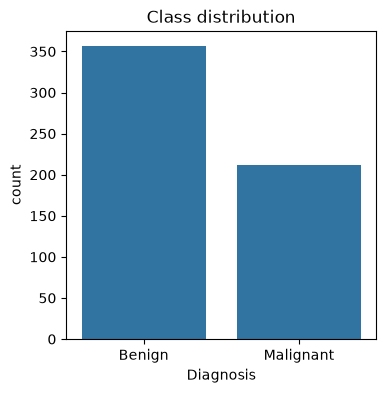

In [16]:
# %% [4] Class balance
counts = df[TARGET].value_counts().rename({0: "Benign", 1: "Malignant"})
print(counts)
print((counts / len(df)).round(3))

plt.figure(figsize=(4, 4))
sns.countplot(x=df[TARGET].map({0: "Benign", 1: "Malignant"}),
              order=["Benign", "Malignant"])
plt.title("Class distribution")
plt.show()

In [17]:
# %% [5] Descriptive statistics (note how different the scales are)
df[features].describe().T[["mean", "std", "min", "max"]]


,mean,std,min,max
mean radius,14.127292,3.524049,6.981000,28.11000
mean texture,19.289649,4.301036,9.710000,39.28000
mean perimeter,91.969033,24.298981,43.790000,188.50000
mean area,654.889104,351.914129,143.500000,2501.00000
mean smoothness,0.096360,0.014064,0.052630,0.16340
mean compactness,0.104341,0.052813,0.019380,0.34540
mean concavity,0.088799,0.079720,0.000000,0.42680
mean concave points,0.048919,0.038803,0.000000,0.20120
mean symmetry,0.181162,0.027414,0.106000,0.30400
mean fractal dimension,0.062798,0.007060,0.049960,0.09744


Top 10 features with the most outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


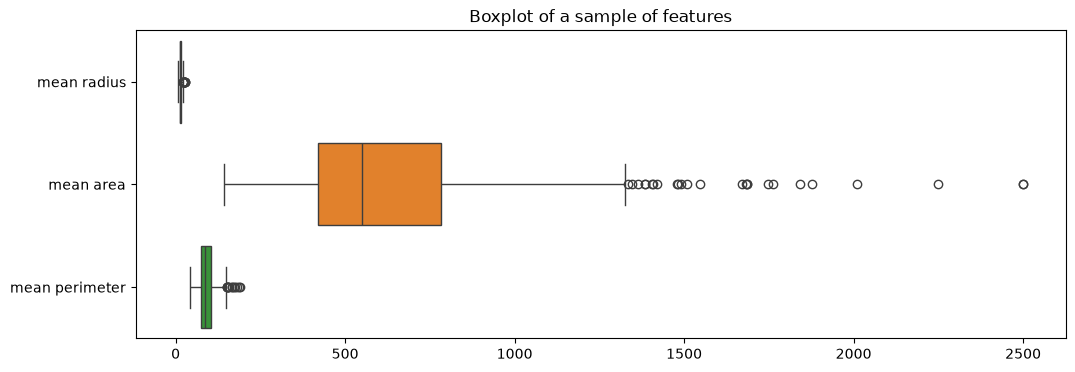

In [18]:
# %% [6] Outliers using the IQR method
q1 = df[features].quantile(0.25)
q3 = df[features].quantile(0.75)
iqr = q3 - q1
mask = (df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)
outliers = mask.sum().sort_values(ascending=False)
print("Top 10 features with the most outliers:")
print(outliers.head(10))

plt.figure(figsize=(12, 4))
sns.boxplot(data=df[["mean radius", "mean area", "mean perimeter"]], orient="h")
plt.title("Boxplot of a sample of features")
plt.show()

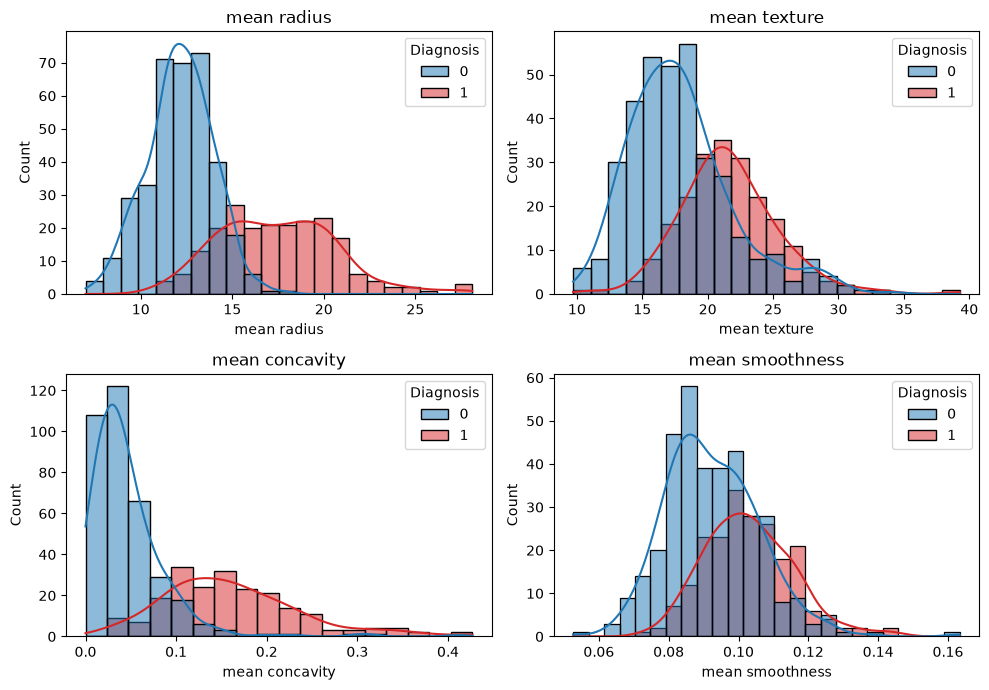

In [19]:
# %% [7] Feature distributions by diagnosis
top = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.ravel(), top):
    sns.histplot(data=df, x=col, hue=TARGET, kde=True, ax=ax,
                 palette={0: "tab:blue", 1: "tab:red"})
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [20]:
# %% [8] Correlation between each feature and the diagnosis
corr_target = df.corr()[TARGET].drop(TARGET).sort_values(ascending=False)
print("Top 5 positive correlations:\n", corr_target.head(5))
print("\nTop 5 negative correlations:\n", corr_target.tail(5))


Top 5 positive correlations:
 worst concave points    0.793566
worst perimeter         0.782914
mean concave points     0.776614
worst radius            0.776454
mean perimeter          0.742636
Name: Diagnosis, dtype: float64

Top 5 negative correlations:
 fractal dimension error    0.077972
symmetry error            -0.006522
texture error             -0.008303
mean fractal dimension    -0.012838
smoothness error          -0.067016
Name: Diagnosis, dtype: float64


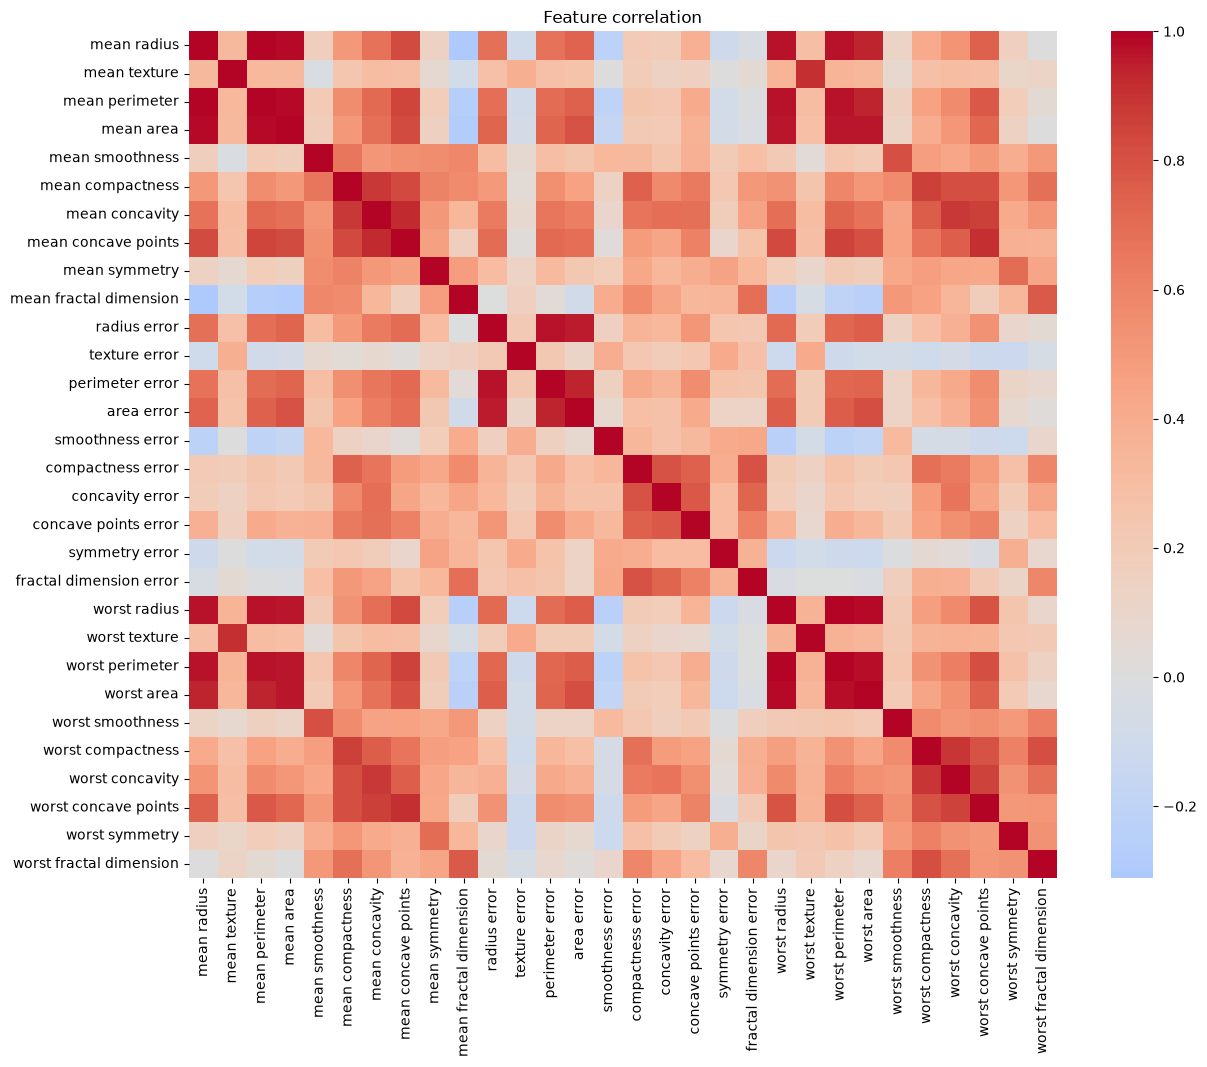

In [21]:
# %% [9] Heatmap of feature-to-feature correlation
plt.figure(figsize=(14, 11))
sns.heatmap(df[features].corr(), cmap="coolwarm", center=0)
plt.title("Feature correlation")
plt.show()


In [22]:
# %% [10] Highly correlated feature pairs (> 0.9)
corr = df[features].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = (upper.stack()
              .loc[lambda s: s > 0.9]
              .sort_values(ascending=False))
print("Number of pairs with correlation > 0.9:", len(pairs))
print(pairs.head(10))

Number of pairs with correlation > 0.9: 21
mean radius      mean perimeter     0.997855
worst radius     worst perimeter    0.993708
mean radius      mean area          0.987357
mean perimeter   mean area          0.986507
worst radius     worst area         0.984015
worst perimeter  worst area         0.977578
radius error     perimeter error    0.972794
mean perimeter   worst perimeter    0.970387
mean radius      worst radius       0.969539
mean perimeter   worst radius       0.969476
dtype: float64
